<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan2/BTVN/Tuan2_BTVN_MachineLearningT2_BTVN_Bai2_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Thong so toi uu:
{'svm__C': 0.1, 'svm__kernel': 'linear'}
CV Accuracy: 0.975
Test Accuracy: 0.9333333333333333
Ma tran nham lan:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


10 CAU HINH TOT NHAT:
                                                     params  mean_test_score  std_test_score
                   {'svm__C': 0.1, 'svm__kernel': 'linear'}         0.975000        0.020412
                     {'svm__C': 1, 'svm__kernel': 'linear'}         0.975000        0.033333
   {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}         0.975000        0.020412
     {'svm__C': 1, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'

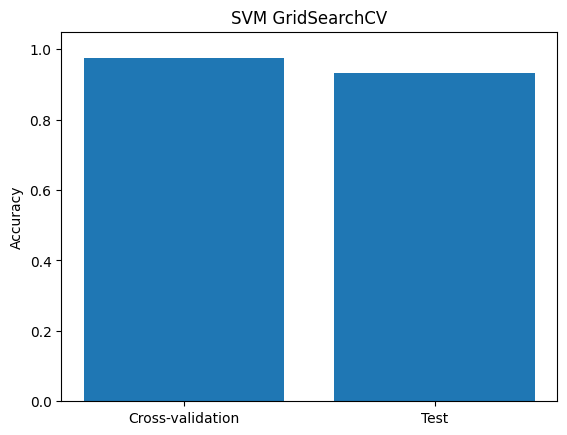

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Nap Iris
iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Tao Pipeline
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("svm", SVC())
])

# 3. Bo thong so can thu
params = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1, 1]
    },
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__gamma": ["scale", 0.1],
        "svm__degree": [2, 3]
    }
]

# 4. GridSearchCV voi 5-fold
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

search = GridSearchCV(
    pipe,
    params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    refit=True
)

search.fit(X_train, y_train)

# 5. Thong so tot nhat
print("Thong so toi uu:")
print(search.best_params_)

print("CV Accuracy:", search.best_score_)

# 6. Danh gia tren test
pred = search.predict(X_test)

accuracy = accuracy_score(y_test, pred)
print("Test Accuracy:", accuracy)

print("Ma tran nham lan:")
print(confusion_matrix(y_test, pred))

print(classification_report(
    y_test, pred,
    target_names=iris.target_names,
    zero_division=0
))

# 7. Bang 10 ket qua CV tot nhat
results = pd.DataFrame(search.cv_results_)
results = results.sort_values("rank_test_score")

print("\n10 CAU HINH TOT NHAT:")
print(results[[
    "params", "mean_test_score", "std_test_score"
]].head(10).to_string(index=False))

# 8. Bieu do
plt.bar(
    ["Cross-validation", "Test"],
    [search.best_score_, accuracy]
)
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("SVM GridSearchCV")
plt.show()
